**Exploratory Data Analysis**

In [167]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Note**
The data is not saved within this repository. You will need to import it into this working directory. After that, run the cell below. 

In [168]:
df = pd.read_csv('ENB2012_data.csv')
df.head(4)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


**Note** The dataframe lacks the descirptive tittles for each feature, so the below cell renames them, while also adding additional information. 

In [169]:
df.rename(columns={'X1':'Relative Compactness',
                    'X2':'Surface Area',
                    'X3':'Wall Area (m^2)',
                    'X4':'Roof Area (m^2)',
                    'X5':'Overall Height (m)',
                    'X6':'Orientation',
                    'X7':'Glazing Area (m^2)',
                    'X8':'Glazing Area Distribution',
                    'Y1':'Heating Load',
                    'Y2':'Cooling Load'}, 
                    inplace=True)

***Basic Information***

**About the Data**

768 simulated buildings.

**Features**
* Relative Compactness: 
* Surface Area: Meters^2
* Wall Area: Meters^2
* Roof Area: Meters^2
* Overall Height: Meters
* Orientation: <-- Treat like Categorical
* Glazing Area: Meters
* Glazing Area Distribution: Meters^2 <-- Treat like Categorical
* Heating Load:
* Cooling Load:


In [170]:
df.head(4)

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Orientation,Glazing Area (m^2),Glazing Area Distribution,Heating Load,Cooling Load
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


In [171]:
#There are 528 rows of null data in the dataset. We will drop them since they are not many and we have enough data to work with.
df.isnull().sum()

Relative Compactness         528
Surface Area                 528
Wall Area (m^2)              528
Roof Area (m^2)              528
Overall Height (m)           528
Orientation                  528
Glazing Area (m^2)           528
Glazing Area Distribution    528
Heating Load                 528
Cooling Load                 528
dtype: int64

These 528 rows are rows of data tha follow the 768th row of actual data. These rows have nothing in them, and accoring to the introductory paper there are only 768 rows of data. This makes them safe to remove from our dataset.

In [172]:
#removed null values
df.dropna(inplace=True)
df.isnull().sum()

Relative Compactness         0
Surface Area                 0
Wall Area (m^2)              0
Roof Area (m^2)              0
Overall Height (m)           0
Orientation                  0
Glazing Area (m^2)           0
Glazing Area Distribution    0
Heating Load                 0
Cooling Load                 0
dtype: int64

In [173]:
#Check for duplicates
df.duplicated().sum()

0

In [174]:
df.nunique()

Relative Compactness          12
Surface Area                  12
Wall Area (m^2)                7
Roof Area (m^2)                4
Overall Height (m)             2
Orientation                    4
Glazing Area (m^2)             4
Glazing Area Distribution      6
Heating Load                 586
Cooling Load                 636
dtype: int64

In [175]:
df[['Orientation', 'Glazing Area Distribution']] = df[['Orientation', 'Glazing Area Distribution']].astype('category')

In [176]:
df.describe(include='number').style.format("{:.2f}") #all Data are numeric and there are no missing values.

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Glazing Area (m^2),Heating Load,Cooling Load
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.76,671.71,318.50,176.60,5.25,0.23,22.31,24.59
std,0.11,88.09,43.63,45.17,1.75,0.13,10.09,9.51
min,0.62,514.50,245.00,110.25,3.50,0.00,6.01,10.90
25%,0.68,606.38,294.00,140.88,3.50,0.10,12.99,15.62
50%,0.75,673.75,318.50,183.75,5.25,0.25,18.95,22.08
75%,0.83,741.12,343.00,220.50,7.00,0.40,31.67,33.13
max,0.98,808.50,416.50,220.50,7.00,0.40,43.10,48.03


In [177]:
df.to_csv('ENB2012_data_cleaned.csv', index=False)

In [178]:
df.describe(include='category').style.format("{:.2f}") #all Data are numeric and there are no missing values.

,Orientation,Glazing Area Distribution
count,768.00,768.00
unique,4.00,6.00
top,2.00,1.00
freq,192.00,144.00


Text(0, 0.5, 'Frequency')

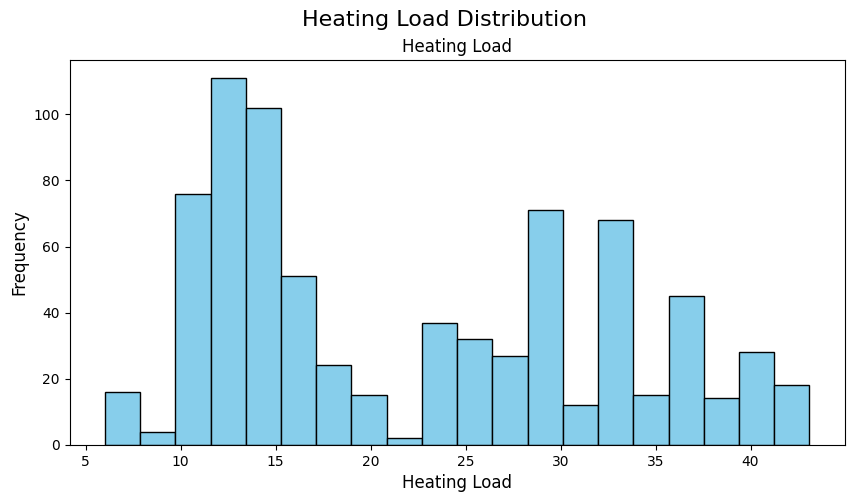

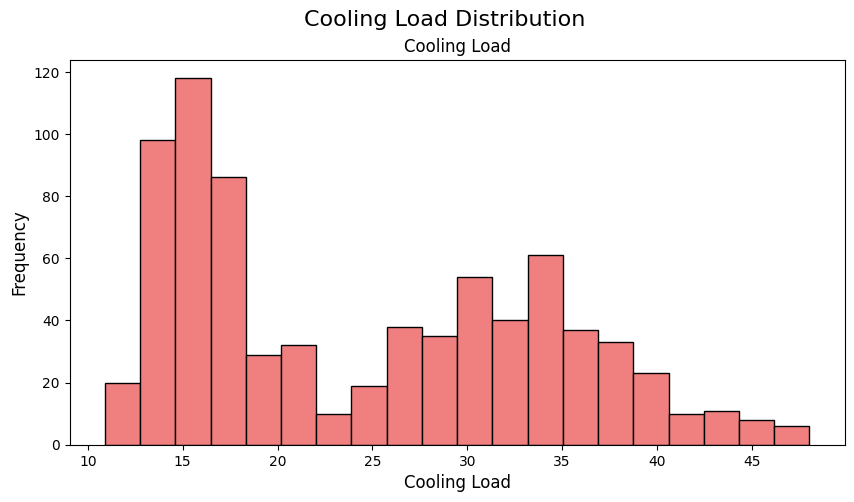

In [179]:
#Histograms for Heating Load and Cooling Load
ax = df[['Heating Load']].hist(bins=20, figsize=(10, 5), grid=False, color='skyblue', edgecolor='black')
plt.suptitle('Heating Load Distribution', fontsize=16)
plt.xlabel('Heating Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

ax = df[['Cooling Load']].hist(bins=20, figsize=(10, 5), grid=False, color='lightcoral', edgecolor='black')
plt.suptitle('Cooling Load Distribution', fontsize=16)
plt.xlabel('Cooling Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

In [180]:
loads = df[['Heating Load', 'Cooling Load']]

summary = loads.agg(['mean', 'median', 'skew']).T
display(summary)

,mean,median,skew
Heating Load,22.307201,18.95,0.360449
Cooling Load,24.587760,22.08,0.395992


Both Cooling Load and Heating Load are unimodal and have mild positive skewness, as evident by their means exeeding their medians, along with the skewness coeficients of .395 and .360 respectively. 

,Heating Load,Cooling Load
Heating Load,1.000000,0.975862
Cooling Load,0.975862,1.000000


,Heating Load,Cooling Load
Heating Load,1.000000,0.972689
Cooling Load,0.972689,1.000000


Share of low-heating designs also low-cooling: 87.0%


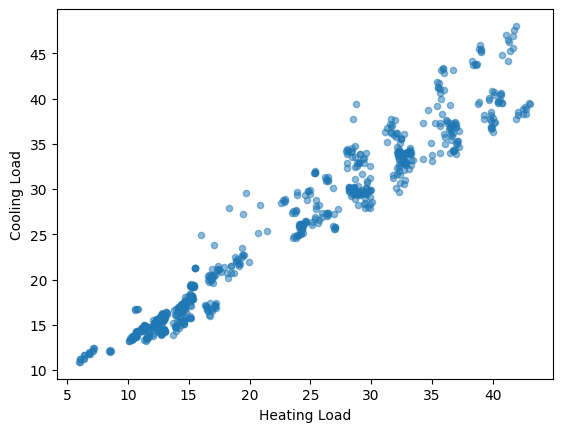

In [181]:
heating = "Heating Load"
cooling = "Cooling Load"

display(df[[heating, cooling]].corr(method="pearson"))
display(df[[heating, cooling]].corr(method="spearman"))

ax = df.plot.scatter(x=heating, y=cooling, alpha=0.5)

low_heating = df[heating] <= df[heating].quantile(0.25)
low_cooling = df[cooling] <= df[cooling].quantile(0.25)

print(
    "Share of low-heating designs also low-cooling:",
    f"{low_cooling[low_heating].mean():.1%}"
)

The share of low-heating designs that are also low-cooling is 100.0%. This indicates a strong positive correlation between heating and cooling loads in the dataset.

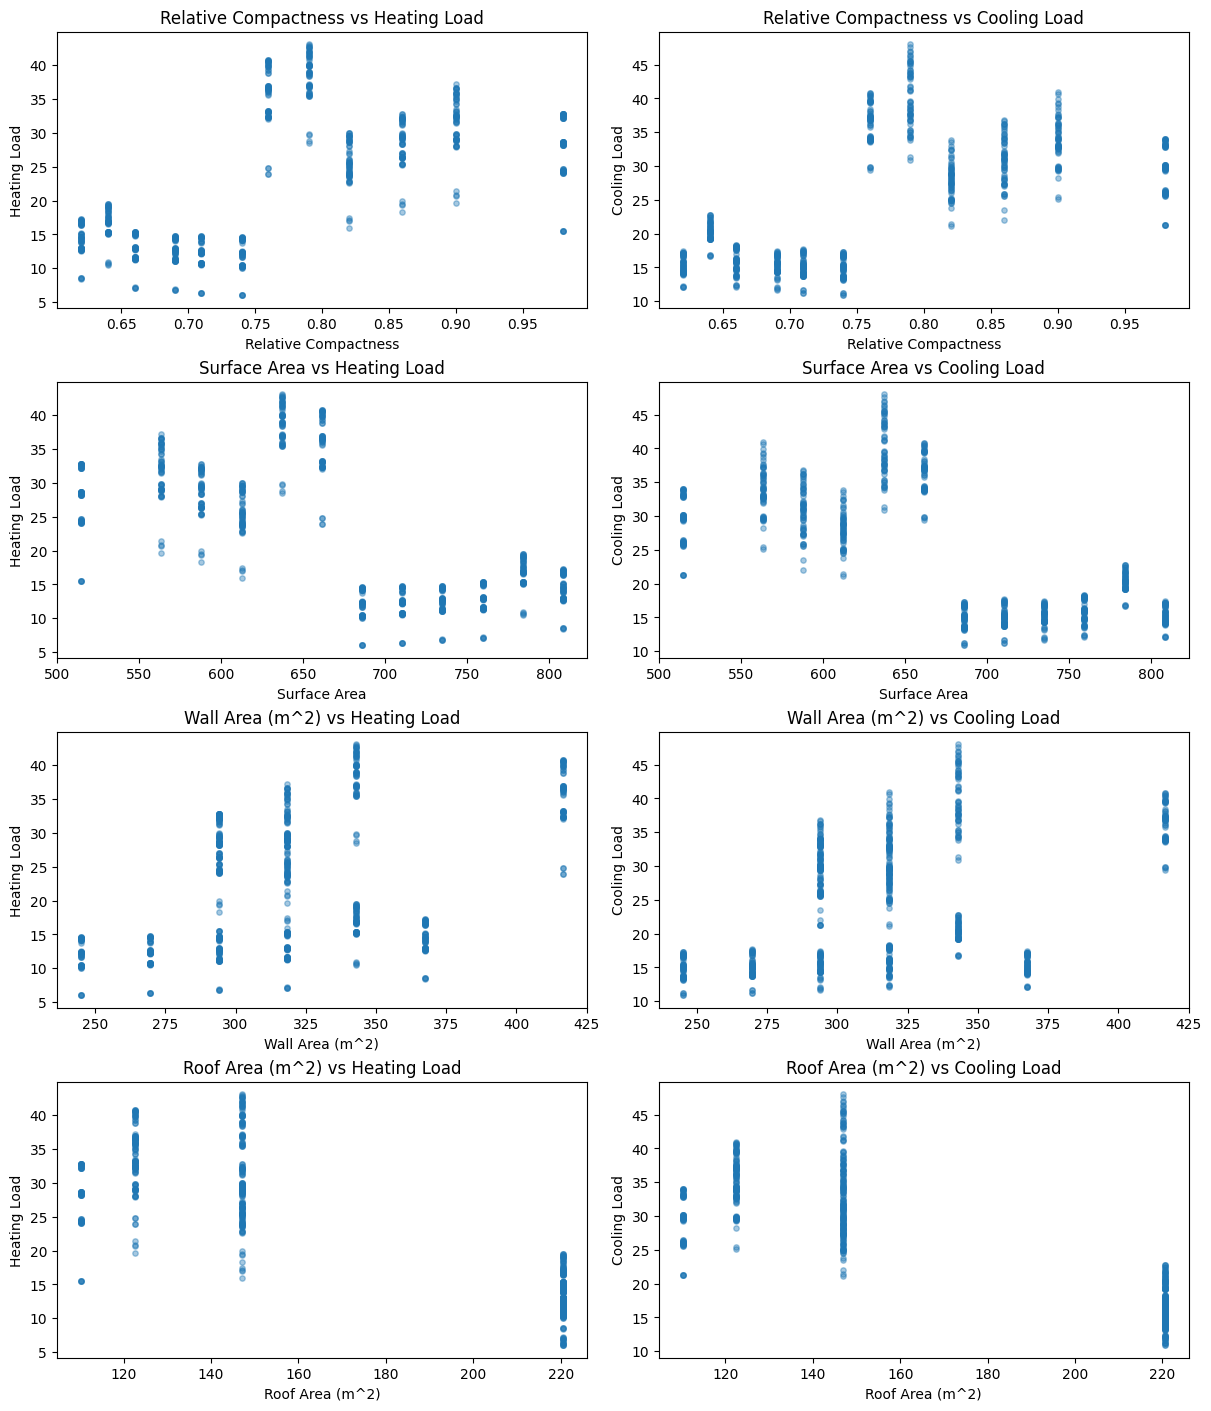

In [182]:
features = [
    'Relative Compactness',
    'Surface Area',
    'Wall Area (m^2)',
    'Roof Area (m^2)'
]
targets = ['Heating Load', 'Cooling Load']

fig, axes = plt.subplots(
    len(features), 2,
    figsize=(12, 14),
    constrained_layout=True
)

for row, feature in enumerate(features):
    for col, target in enumerate(targets):
        ax = axes[row, col]
        ax.scatter(df[feature], df[target], alpha=0.4, s=15)
        ax.set_xlabel(feature)
        ax.set_ylabel(target)
        ax.set_title(f'{feature} vs {target}')

plt.show()